CA1 - Machine Learning
Predicting Mental Health Treatment Seeking Behaviour Using Machine Learning

Student Name: Dolgorsuren Ochirsuren

Module: Machine Learning

Lecturer: Dr. Muhammad Iqbal

In [113]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import ( train_test_split, cross_val_score, GridSearchCV)

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import ( accuracy_score, confusion_matrix, classification_report)

2. LOAD DATASET

In [114]:
df = pd.read_csv("mental_health.csv.csv")

In [115]:
print(df.shape)

(1433, 63)


In [116]:
df.head()

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes


3. DATA OVERVIEW

In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 63 columns):
 #   Column                                                                                                                                                                            Non-Null Count  Dtype  
---  ------                                                                                                                                                                            --------------  -----  
 0   Are you self-employed?                                                                                                                                                            1433 non-null   int64  
 1   How many employees does your company or organization have?                                                                                                                        1146 non-null   str    
 2   Is your employer primarily a tech company/organization?                

In [118]:
df.describe()

,Are you self-employed?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Do you have medical coverage (private insurance or state-provided) which includes treatment of mental health issues?,Do you have previous employers?,Have you ever sought treatment for a mental health issue from a mental health professional?,What is your age?
count,1433.000000,1146.000000,263.000000,287.000000,1433.000000,1433.000000,1433.000000
mean,0.200279,0.770506,0.942966,0.644599,0.882066,0.585485,34.286113
std,0.400349,0.420691,0.232350,0.479471,0.322643,0.492810,11.290931
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,28.000000
50%,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,33.000000
75%,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,39.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,323.000000


4. MISSING VALUES

In [119]:
df.isnull().sum()

Are you self-employed?                                                                  0
How many employees does your company or organization have?                            287
Is your employer primarily a tech company/organization?                               287
Is your primary role within your company related to tech/IT?                         1170
Does your employer provide mental health benefits as part of healthcare coverage?     287
                                                                                     ... 
What US state or territory do you live in?                                            593
What country do you work in?                                                            0
What US state or territory do you work in?                                            582
Which of the following best describes your work position?                               0
Do you work remotely?                                                                   0
Length: 63

In [120]:
for col in df.select_dtypes(include=['object', 'string']).columns: df[col] = df[col].fillna("Unknown")

In [121]:
for col in df.select_dtypes(include=['int64','float64']).columns: df[col] = df[col].fillna(df[col].median())

5. DUPLICATES

In [122]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [123]:
df = df.drop_duplicates()

6. CHOOSE TARGET VARIABLE

In [124]:
target = "Have you ever sought treatment for a mental health issue from a mental health professional?"

7. TARGET DISTRIBUTION

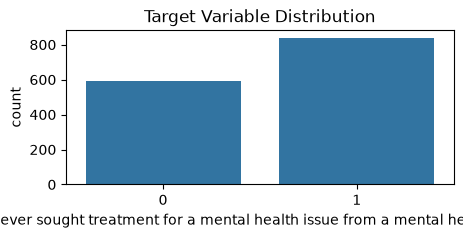

In [125]:
plt.figure(figsize=(5,2))

sns.countplot(x=df[target])

plt.title("Target Variable Distribution")
plt.show()

##Exploratory Data Analysis (EDA)

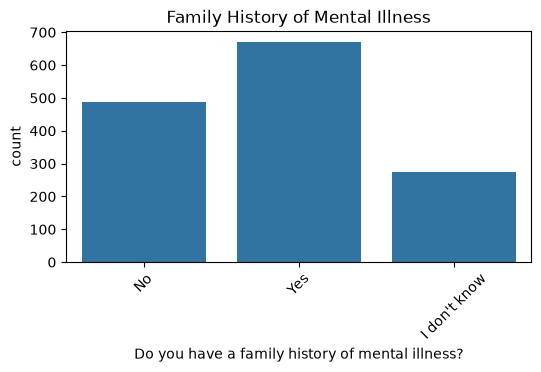

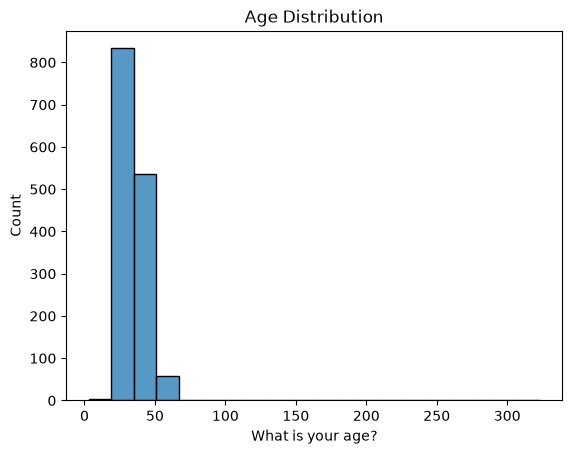

In [131]:
plt.figure(figsize=(6,3))

sns.countplot(x=df["Do you have a family history of mental illness?"])

plt.title("Family History of Mental Illness")

plt.xticks(rotation=45)

plt.show()

sns.histplot(df["What is your age?"],bins=20)

plt.title("Age Distribution")

plt.show()

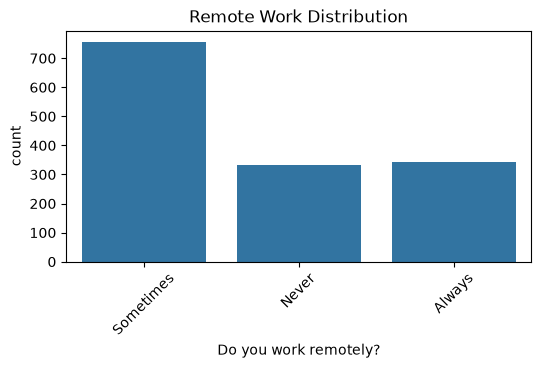

In [132]:
plt.figure(figsize=(6,3))

sns.countplot(x=df["Do you work remotely?"])

plt.title("Remote Work Distribution")

plt.xticks(rotation=45)

plt.show()


8. LABEL ENCODING

In [133]:
encoder = LabelEncoder()

for col in df.select_dtypes(include=['object','string']).columns: df[col] = encoder.fit_transform(df[col].astype(str))

 9. FEATURES AND TARGET

In [134]:
X = df.drop( target, axis=1)

y = df[target]

print(X.shape)
print(y.shape)

(1433, 62)
(1433,)


10. RANDOM FOREST
# 5%,15%,25%

In [135]:
splits = [0.05,0.15,0.25]

rf_results = []

for split in splits: X_train,X_test,y_train,y_test = train_test_split( X, y,test_size=split, random_state=42)

rf = RandomForestClassifier(random_state=42)

rf.fit(X_train,y_train)

pred = rf.predict(X_test)

acc = accuracy_score(y_test,pred)

rf_results.append(acc)

print(f"RF Split={split} Accuracy={acc:.4f}")

RF Split=0.25 Accuracy=0.8524


11. SVM
# 5%,15%,25%

In [136]:
svm_results = []

for split in splits:

    X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=split,random_state=42)

    svm = SVC()

    svm.fit(X_train,y_train)

    pred = svm.predict(X_test)

    acc = accuracy_score(y_test,pred)

    svm_results.append(acc)

    print(f"SVM Split={split} Accuracy={acc:.4f}")


SVM Split=0.05 Accuracy=0.7361
SVM Split=0.15 Accuracy=0.7721
SVM Split=0.25 Accuracy=0.7577


 12. CROSS VALIDATION

In [137]:
rf = RandomForestClassifier(random_state=42)


cv_scores = cross_val_score(rf,X,y,cv=5)


print("CV Scores:", cv_scores)

print("Mean CV Score:", cv_scores.mean())

CV Scores: [0.87456446 0.87108014 0.87456446 0.85314685 0.86363636]
Mean CV Score: 0.8673984552033331


13. HYPERPARAMETER TUNING

In [138]:
X_train,X_test,y_train,y_test = train_test_split( X, y, test_size=0.25, random_state=42)

params = {"n_estimators":[100,200],"max_depth":[5, 10, None],"min_samples_split":[2,5]}

grid = GridSearchCV(RandomForestClassifier( random_state=42),params,cv=5,scoring="accuracy")

grid.fit(X_train,y_train)

print("Best Parameters")
print(grid.best_params_)

print("Best CV Accuracy")
print(grid.best_score_)

Best Parameters
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Accuracy
0.8742795044555531


14. BEST MODEL

In [139]:
best_model = grid.best_estimator_

pred = best_model.predict(X_test)

15. FINAL ACCURACY

In [140]:
print(accuracy_score(y_test,pred))

0.8579387186629527


16. CLASSIFICATION REPORT

In [141]:
print(classification_report( y_test, pred))

              precision    recall  f1-score   support

           0       0.81      0.85      0.83       143
           1       0.89      0.87      0.88       216

    accuracy                           0.86       359
   macro avg       0.85      0.86      0.85       359
weighted avg       0.86      0.86      0.86       359



17. CONFUSION MATRIX

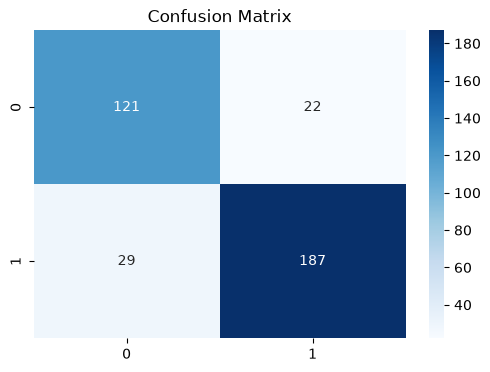

In [142]:
cm = confusion_matrix(y_test,pred)

plt.figure(figsize=(6,4))

sns.heatmap(cm,annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")

plt.show()

18. FEATURE IMPORTANCE

In [143]:
importance = pd.DataFrame({"Feature":X.columns,"Importance":best_model.feature_importances_})

importance = importance.sort_values(by="Importance",ascending=False)

print(importance.head(10))


                                              Feature  Importance
50  Have you been diagnosed with a mental health c...    0.169388
51  If so, what condition(s) were you diagnosed with?    0.150996
46  Have you had a mental health disorder in the p...    0.134848
53  If you have a mental health issue, do you feel...    0.063971
48  If yes, what condition(s) have you been diagno...    0.054594
52  If you have a mental health issue, do you feel...    0.052253
47    Do you currently have a mental health disorder?    0.039727
39                                  Why or why not?.1    0.016787
37                                    Why or why not?    0.016640
45    Do you have a family history of mental illness?    0.015653


19. FEATURE IMPORTANCE CHART

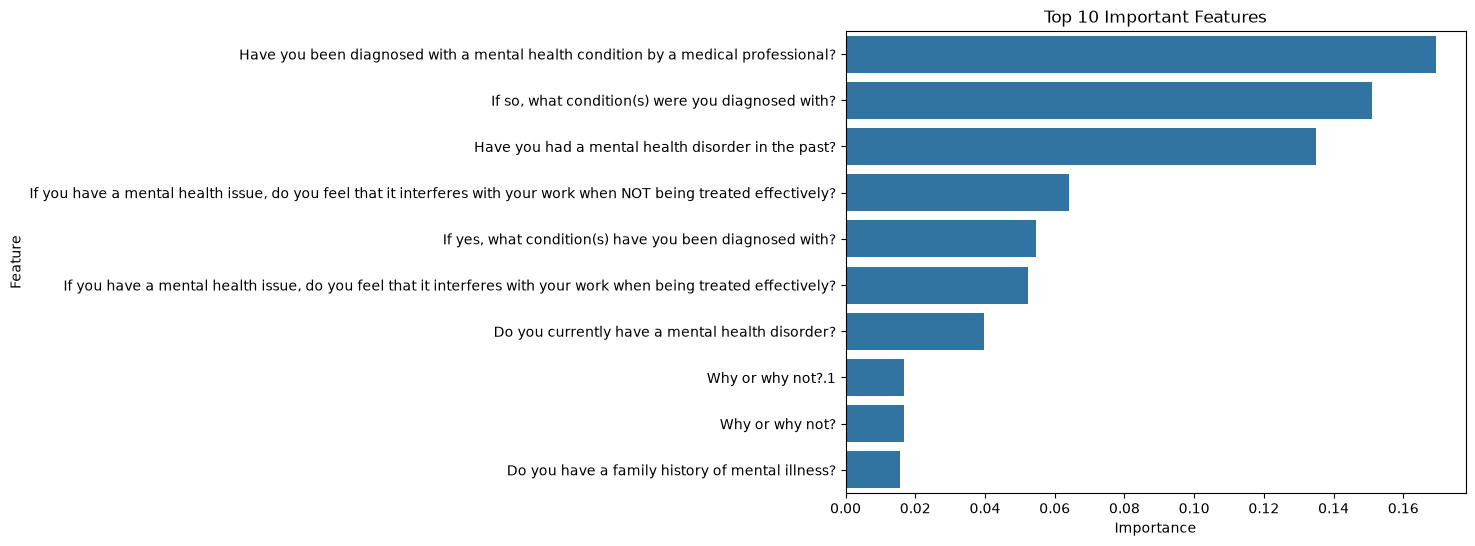

In [144]:
plt.figure(figsize=(8,6))

sns.barplot(data=importance.head(10),x="Importance",y="Feature")

plt.title("Top 10 Important Features")

plt.show()

20. MODEL COMPARISON

In [145]:
print(rf_results)
print(svm_results)

[0.8523676880222841]
[0.7361111111111112, 0.772093023255814, 0.7576601671309192]


In [146]:
splits = [0.05, 0.15, 0.25]

rf_results = []

for split in splits:X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=split, random_state=42)

rf = RandomForestClassifier(random_state=42)

rf.fit(X_train, y_train)

pred = rf.predict(X_test)

acc = accuracy_score(y_test, pred)

rf_results.append(acc)

print(f"RF Split={split} Accuracy={acc:.4f}")

print("RF Results:", rf_results)

RF Split=0.25 Accuracy=0.8524
RF Results: [0.8523676880222841]


Overfitting / Generalisation

In [147]:
train_accuracy = best_model.score(X_train, y_train)

test_accuracy = best_model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.9702048417132216
Testing Accuracy: 0.8579387186629527


Conclusion
In this project, I used machine learning to predict whether a person may seek mental health treatment.

I used two models: Random Forest and Support Vector Machine (SVM). The results showed that Random Forest performed better than SVM. The Random Forest model achieved an accuracy of 85.24%, while the SVM model achieved 75.77%.

I also used GridSearchCV to improve the Random Forest model. The best parameters were max_depth = 10, min_samples_split = 5 and n_estimators = 100. The best cross-validation accuracy was 87.43%.

The results show that machine learning can help predict mental health treatment behaviour. Some features had a stronger impact on the prediction than others.

Overall, Random Forest was the best model for this dataset and produced good prediction results.